# Научно-исследовательский проект по машинному обучению

## Тема: Анализ успеваемости студентов, предобработка данных, решение задачи регрессии и построение нейронной сети.

### Работу выполнил: Вагин Павел Игоревич

##### Импорт библиотек, для работы с таблицами, матрицами, и построения графиков


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pandas.core.interchange import column

### Загрузка исходного датасета
#####

In [3]:
df = pd.read_csv('pandas_ml_dataset.csv')
df.head()

,student_id,age,subject,study_hours_per_day,sleep_hours_per_night,gaming_hours_per_day,attendance_percent,homework_completed_percent,class_participation,preferred_learning_format,test_score,passed_test
0,S001,11,language,2.1,NaN,3.9,100,82.0,medium,videos,62,yes
1,S002,15,math,2.1,8.0,1.7,99,86.0,medium,reading,60,yes
2,S003,14,math,2.3,7.3,6.2,90,50.0,high,reading,55,no
3,S004,13,science,1.6,8.3,1.9,82,81.0,medium,videos,58,no
4,S005,13,science,1.3,7.9,3.8,89,70.0,low,videos,43,no


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   student_id                  180 non-null    str    
 1   age                         180 non-null    int64  
 2   subject                     180 non-null    str    
 3   study_hours_per_day         180 non-null    float64
 4   sleep_hours_per_night       173 non-null    float64
 5   gaming_hours_per_day        174 non-null    float64
 6   attendance_percent          180 non-null    int64  
 7   homework_completed_percent  176 non-null    float64
 8   class_participation         180 non-null    str    
 9   preferred_learning_format   175 non-null    str    
 10  test_score                  180 non-null    int64  
 11  passed_test                 180 non-null    str    
dtypes: float64(4), int64(3), str(5)
memory usage: 17.0 KB


##### Предобработка данных: Обработка пропущенных значений (NaN) и кодирование признаков

In [5]:
df['sleep_hours_per_night'] = df['sleep_hours_per_night'].fillna(df['sleep_hours_per_night'].mean())
df.info() #заполнили sleep_hours_per_night вместо значения 173 на значения 180

<class 'pandas.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   student_id                  180 non-null    str    
 1   age                         180 non-null    int64  
 2   subject                     180 non-null    str    
 3   study_hours_per_day         180 non-null    float64
 4   sleep_hours_per_night       180 non-null    float64
 5   gaming_hours_per_day        174 non-null    float64
 6   attendance_percent          180 non-null    int64  
 7   homework_completed_percent  176 non-null    float64
 8   class_participation         180 non-null    str    
 9   preferred_learning_format   175 non-null    str    
 10  test_score                  180 non-null    int64  
 11  passed_test                 180 non-null    str    
dtypes: float64(4), int64(3), str(5)
memory usage: 17.0 KB


In [6]:
df['gaming_hours_per_day'].max()

np.float64(7.0)

In [7]:
mask = df['gaming_hours_per_day'].isna()

df.loc[mask, 'gaming_hours_per_day'] = np.random.uniform(0, 7, mask.sum())
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   student_id                  180 non-null    str    
 1   age                         180 non-null    int64  
 2   subject                     180 non-null    str    
 3   study_hours_per_day         180 non-null    float64
 4   sleep_hours_per_night       180 non-null    float64
 5   gaming_hours_per_day        180 non-null    float64
 6   attendance_percent          180 non-null    int64  
 7   homework_completed_percent  176 non-null    float64
 8   class_participation         180 non-null    str    
 9   preferred_learning_format   175 non-null    str    
 10  test_score                  180 non-null    int64  
 11  passed_test                 180 non-null    str    
dtypes: float64(4), int64(3), str(5)
memory usage: 17.0 KB


In [8]:
df['homework_completed_percent'].max()

np.float64(100.0)

In [9]:
mask = df['homework_completed_percent'].isna()
df.loc[mask, 'homework_completed_percent'] = np.random.uniform (31.0, 100., mask.sum())
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   student_id                  180 non-null    str    
 1   age                         180 non-null    int64  
 2   subject                     180 non-null    str    
 3   study_hours_per_day         180 non-null    float64
 4   sleep_hours_per_night       180 non-null    float64
 5   gaming_hours_per_day        180 non-null    float64
 6   attendance_percent          180 non-null    int64  
 7   homework_completed_percent  180 non-null    float64
 8   class_participation         180 non-null    str    
 9   preferred_learning_format   175 non-null    str    
 10  test_score                  180 non-null    int64  
 11  passed_test                 180 non-null    str    
dtypes: float64(4), int64(3), str(5)
memory usage: 17.0 KB


Заменить пропущенное значение в столбце 'preferred_learning_format'

In [10]:
df['preferred_learning_format'] = df['preferred_learning_format'].fillna('Unknown')
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   student_id                  180 non-null    str    
 1   age                         180 non-null    int64  
 2   subject                     180 non-null    str    
 3   study_hours_per_day         180 non-null    float64
 4   sleep_hours_per_night       180 non-null    float64
 5   gaming_hours_per_day        180 non-null    float64
 6   attendance_percent          180 non-null    int64  
 7   homework_completed_percent  180 non-null    float64
 8   class_participation         180 non-null    str    
 9   preferred_learning_format   180 non-null    str    
 10  test_score                  180 non-null    int64  
 11  passed_test                 180 non-null    str    
dtypes: float64(4), int64(3), str(5)
memory usage: 17.0 KB


In [11]:
df.head()


,student_id,age,subject,study_hours_per_day,sleep_hours_per_night,gaming_hours_per_day,attendance_percent,homework_completed_percent,class_participation,preferred_learning_format,test_score,passed_test
0,S001,11,language,2.1,8.043931,3.9,100,82.0,medium,videos,62,yes
1,S002,15,math,2.1,8.000000,1.7,99,86.0,medium,reading,60,yes
2,S003,14,math,2.3,7.300000,6.2,90,50.0,high,reading,55,no
3,S004,13,science,1.6,8.300000,1.9,82,81.0,medium,videos,58,no
4,S005,13,science,1.3,7.900000,3.8,89,70.0,low,videos,43,no


Удаляем колонки с категориальными факторами, не влияющие на конечный результат

In [12]:
df = df.drop(columns=['student_id', 'subject', 'passed_test'])
df.head()

,age,study_hours_per_day,sleep_hours_per_night,gaming_hours_per_day,attendance_percent,homework_completed_percent,class_participation,preferred_learning_format,test_score
0,11,2.1,8.043931,3.9,100,82.0,medium,videos,62
1,15,2.1,8.000000,1.7,99,86.0,medium,reading,60
2,14,2.3,7.300000,6.2,90,50.0,high,reading,55
3,13,1.6,8.300000,1.9,82,81.0,medium,videos,58
4,13,1.3,7.900000,3.8,89,70.0,low,videos,43


Заменяем на числа те, категориальные факторы, для которых можно подобрать логически новое значение

In [13]:
df['class_participation'] = df['class_participation'].replace({'low': 1,
                                                               'medium': 2,
                                                               'high': 3})
df.head()

,age,study_hours_per_day,sleep_hours_per_night,gaming_hours_per_day,attendance_percent,homework_completed_percent,class_participation,preferred_learning_format,test_score
0,11,2.1,8.043931,3.9,100,82.0,2,videos,62
1,15,2.1,8.000000,1.7,99,86.0,2,reading,60
2,14,2.3,7.300000,6.2,90,50.0,3,reading,55
3,13,1.6,8.300000,1.9,82,81.0,2,videos,58
4,13,1.3,7.900000,3.8,89,70.0,1,videos,43


Заменяем один столбец с категориальными факторами на несколько с численными

In [14]:
df = pd.get_dummies(df, columns=['preferred_learning_format'], dtype=int)
df.head()

,age,study_hours_per_day,sleep_hours_per_night,gaming_hours_per_day,attendance_percent,homework_completed_percent,class_participation,test_score,preferred_learning_format_Unknown,preferred_learning_format_group_work,preferred_learning_format_practice,preferred_learning_format_reading,preferred_learning_format_videos
0,11,2.1,8.043931,3.9,100,82.0,2,62,0,0,0,0,1
1,15,2.1,8.000000,1.7,99,86.0,2,60,0,0,0,1,0
2,14,2.3,7.300000,6.2,90,50.0,3,55,0,0,0,1,0
3,13,1.6,8.300000,1.9,82,81.0,2,58,0,0,0,0,1
4,13,1.3,7.900000,3.8,89,70.0,1,43,0,0,0,0,1


In [15]:
df['attendance_percent'] = df['attendance_percent']/100
df['homework_completed_percent'] = df['homework_completed_percent']/100

 ##### Линейная регрессия: Обучение одного нейрона градиентным спуском

In [16]:
X = df.drop(columns = ['test_score']).to_numpy()
Y = df['test_score'].to_numpy()

In [47]:
X.shape

(180, 12)

In [18]:
np.random.seed(54)

indaces = np.random.permutation(len(X))

train_end = int(0.7 * len(X))
valid_end = int(0.85 * len(X))

train_idx = indaces[:train_end]
valid_idx = indaces[train_end:valid_end]
test_idx = indaces[valid_end:]

X_train, Y_train = X[train_idx], Y[train_idx]
X_valid, Y_valid = X[valid_idx], Y[valid_idx]
X_test, Y_test = X[test_idx], Y[test_idx]

X_train.shape

(125, 12)

Создаем матрицу параметров

In [19]:
W = np.zeros(12,)
b = 0

In [20]:
y_pred = X_train @ W + b
y_pred

array([0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,
       0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,
       0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,
       0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,
       0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,
       0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,
       0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,
       0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,
       0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,
       0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0], dtype=object)

Обучение одного конкертного нейрона

In [21]:
epochs = 100
errors = []
errors_val = []

alpha = 0.0001
epsilon = 0.0001

mse = 1/X_train.shape[0] * ((Y_train - y_pred)**(2)).sum()
errors.append(mse)

for epoch in range(epochs):
    dW = (2/X_train.shape[0]) * (X_train.T @ (y_pred - Y_train))
    db = (2/X_train.shape[0]) * np.sum(y_pred - Y_train)

    W = W - alpha * dW
    b = b - alpha * db

    y_pred = X_train @ W + b
    mse = 1/X_train.shape[0] * ((Y_train - y_pred)**(2)).sum()
    errors.append(mse)

    y_pred_val = X_valid @ W + b

    mse_val = 1/X_train.shape[0] * ((Y_valid - y_pred_val)**(2)).sum()
    errors_val.append(mse_val)

    if abs(errors[-1] - errors[-2]) < epsilon:
        print(epoch) #выведет на каком шаге обучение разница между текущей и предыдущей ошибками
        break
print('Препоследняя ошибка: ', errors[-2])
print('Последняя ошибка: ', errors[-1]) #последняя ошибка
print('Минимальная ошибка: ', min(errors)) #минимальная ошибка

Препоследняя ошибка:  128.0004924064415
Последняя ошибка:  127.97559706301001
Минимальная ошибка:  127.97559706301001


In [22]:
print('Последняя ошибка на валидационной выборке: ', errors_val[-1])

Последняя ошибка на валидационной выборке:  27.754291452577792


### Вывод графика ошибки как изменялась ошибка на валидационной и тренировчной выборке

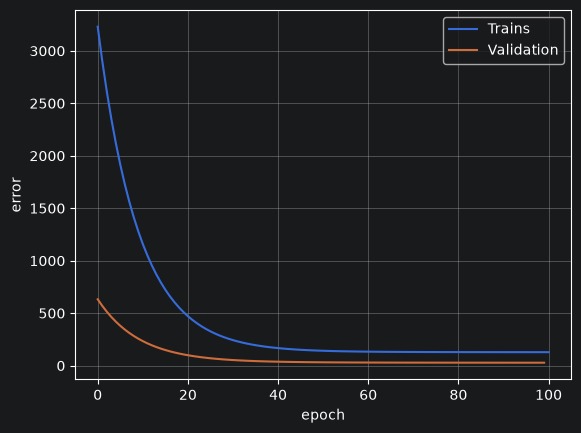

In [23]:
plt.plot(errors, label = 'Trains') #если хотим с конкретной точки смотреть, то errors[30:]
plt.plot(errors_val, label = 'Validation') #если хотим с конкретной точки смотреть, то errors_val[30:]
plt.xlabel('epoch')
plt.ylabel('error')
plt.legend()
plt.grid()
plt.show()

In [24]:
y_pred_test = X_test @ W + b
mse = (1/X_test.shape[0]) * (((y_pred_test - Y_test) ** 2).sum())
print('Ошибка на тестовой выборке: ', mse)

Ошибка на тестовой выборке:  126.24055467021775


In [25]:
y_pred_test #наш нейрон, который предсказывает значения

array([59.281914030714155, 53.55971956963714, 47.43771355186919,
       58.84648321743707, 52.41323778887059, 53.95160172446463,
       53.96875845152169, 55.09844013307528, 52.99776808676032,
       59.94364769522653, 55.77277771713864, 54.979613111331716,
       49.84140661810138, 56.79164991950026, 54.457921312892864,
       61.527836693757926, 49.864059969885375, 45.07310149625403,
       46.67012050224619, 49.48749540678722, 58.79636628371588,
       51.30576914528242, 61.76081848504209, 59.86906980903487,
       58.07367077900794, 53.482255738002664, 57.62020428799239],
      dtype=object)

In [26]:
Y_test #реальные значение из таблицы

array([52, 57, 47, 60, 66, 66, 63, 57, 50, 74, 29, 61, 43, 68, 56, 67, 79,
       48, 70, 49, 62, 42, 60, 70, 57, 66, 57])

##### Многослойный перцептрон: Построение и обучение полносвязной нейронной сети (MLP) с ReLU
##### Переходим к созданию нейронной сети

In [27]:
n_inputs = X_train.shape[1]
n_hidden1 = 4
n_hidden2 = 3
n_output = 1


W1 = np.random.randn(n_inputs, n_hidden1)
b1 = np.zeros((1, n_hidden1))

W2 = np.random.randn(n_hidden1, n_hidden2)
b2 = np.zeros((1, n_hidden2))

W3 = np.random.randn(n_hidden2, n_output)
b3 = np.zeros((1, n_output))


In [28]:
W1

array([[ 0.61350587, -0.13581254,  1.1125468 , -0.94479001],
       [ 1.09115507, -2.78628976, -0.34858565, -0.73702205],
       [-0.4858842 , -0.02268579,  1.19136751,  0.67623794],
       [-1.20897912,  0.92554081, -0.71172981, -1.78846606],
       [-0.02190966,  0.27923011,  1.0054736 , -0.61374155],
       [ 0.39530195, -1.15456928, -0.30562426,  1.61982231],
       [ 1.03240144,  0.62708962,  0.73824739, -0.68592645],
       [ 1.87305874,  1.8928456 ,  0.77442264, -0.29151071],
       [-0.91158862, -0.35847952,  0.61634483, -1.29134324],
       [ 2.10226055, -0.26559381, -0.10245742, -1.90689349],
       [-0.94310711,  0.66214189,  1.3431848 , -0.76079575],
       [ 0.06830046,  1.78829981, -0.76089029,  0.15672773]])

In [29]:
y_df = pd.DataFrame({"y_pred": np.asarray(np.int8(y_pred_test)).reshape(-1),
                    "y_real": np.asarray(Y_test).reshape(-1)})
y_df

,y_pred,y_real
0,59,52
1,53,57
2,47,47
3,58,60
4,52,66
5,53,66
6,53,63
7,55,57
8,52,50
9,59,74


In [30]:
Y_train.shape

(125,)

In [31]:
Y_train = Y_train.reshape(-1, 1)
Y_valid = Y_valid.reshape(-1, 1)
Y_test = Y_test.reshape(-1, 1)

In [32]:
Y_train.shape

(125, 1)

In [33]:
epochs = 1000
alpha = 0.0001

best_param = []

train_errors = []
valid_errors = []

best_epoch = 0

def Relu(x):
    return np.maximum(0, x)

def de_relu(x):
    return (x>0).astype(float)

for epoch in range(epochs):
    sum_x1_w1 = X_train @ W1 + b1
    sum_after_function1 = Relu(sum_x1_w1)

    Z2 = sum_after_function1 @ W2 + b2
    A2 = Relu(Z2)

    y_pred = A2 @ W3 + b3

    train_loss = (1/X_train.shape[0])*((y_pred - Y_train)**2).sum()
    train_errors.append(train_loss)

    dZ3 = (2/X_train.shape[0])*(y_pred - Y_train)
    change_weights_3 = A2.T @ dZ3
    db3 = dZ3.sum()

    # print(dZ3.shape, W3.T.shape)

    dA2 = dZ3 @ W3.T
    dZ2 = dA2 * de_relu(Z2)
    dW2 = sum_after_function1.T @ dZ2
    db2 = dZ2.sum()

    dA1 = dZ2 @ W2.T
    dZ1 = dA1 * de_relu(sum_x1_w1)
    dW1 = X_train.T @ dZ1
    db1 = sum_x1_w1.sum()


    W3 = W3 - alpha * change_weights_3
    W2 = W2 - alpha * dW2
    W1 = W1 - alpha * dW1

    b3 = b3 - alpha * db3
    b2 = b2 - alpha * db2
    b1 = b1 - alpha * db1


    A1_val = Relu(X_valid @ W1 + b1)
    A2_val = Relu(A1_val @ W2 + b2)

    y_pred_val = A2_val @ W3 + b3

    valid_loss = (1/X_valid.shape[0]) * ((y_pred_val - Y_valid)**2).sum()
    valid_errors.append(valid_loss)

print(valid_errors[-1])
print(train_errors[-1])



81.66292475392329
89.80157243550669


Проверим как отработает наша нейросеть на тестовой выборке

In [34]:
A1_test = Relu(X_test @ W1 + b1)
A2_test = Relu(A1_test @ W2 + b2)
y_pred_test = A2_test @ W3 + b3

test_loss = (1/X.shape[0]) * ((y_pred_test - Y_test)**2).sum()
test_loss

19.920217796064108

Строим графики как улучшалось обучение нейросети

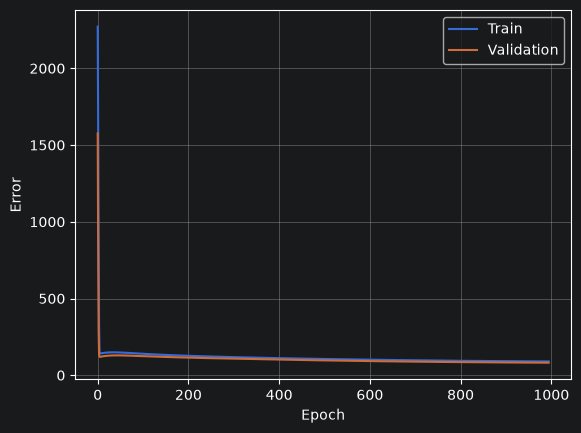

In [35]:
plt.plot(train_errors[5:], label = "Train")
plt.plot(valid_errors[5:], label = "Validation")
plt.xlabel("Epoch")
plt.ylabel("Error")
plt.legend()
plt.grid()
plt.show()

Представим в виде таблички полученные и целевые параметры

In [36]:
y_data = pd.DataFrame({"Real": np.asarray(Y_test).reshape(-1),
                        "Predicted": np.asarray(np.int8(y_pred_test)).reshape(-1)})

y_data

,Real,Predicted
0,52,60
1,57,51
2,47,46
3,60,59
4,66,44
5,66,54
6,63,52
7,57,53
8,50,50
9,74,69


In [37]:
df.head()

,age,study_hours_per_day,sleep_hours_per_night,gaming_hours_per_day,attendance_percent,homework_completed_percent,class_participation,test_score,preferred_learning_format_Unknown,preferred_learning_format_group_work,preferred_learning_format_practice,preferred_learning_format_reading,preferred_learning_format_videos
0,11,2.1,8.043931,3.9,1.00,0.82,2,62,0,0,0,0,1
1,15,2.1,8.000000,1.7,0.99,0.86,2,60,0,0,0,1,0
2,14,2.3,7.300000,6.2,0.90,0.50,3,55,0,0,0,1,0
3,13,1.6,8.300000,1.9,0.82,0.81,2,58,0,0,0,0,1
4,13,1.3,7.900000,3.8,0.89,0.70,1,43,0,0,0,0,1


##### Бинарная классификация: Логистический нейрон и функция активации Сигмоида

In [38]:
df_bin = pd.read_csv('pandas_ml_dataset.csv')
df_bin = df_bin['passed_test']
df_bin.head()

0    yes
1    yes
2     no
3     no
4     no
Name: passed_test, dtype: str

In [39]:
df_bin = df_bin.replace({'yes':1,
                         'no': 0})
df_bin.head()

0    1
1    1
2    0
3    0
4    0
Name: passed_test, dtype: object

In [40]:
y = df_bin.to_numpy()
y.shape

(180,)

In [41]:
y_train = y[train_idx].reshape(-1, 1)
y_valid = y[valid_idx].reshape(-1, 1)
y_test = y[test_idx].reshape(-1, 1)

In [42]:
def sigmoid(x):
    return 1/(1 + np.exp(-x))
def de_sigmoid(x):
    s = sigmoid(x)
    return s * (1 - s)

In [43]:
W1 = np.random.randn(int(X_train.shape[1]), 1)
b = 0

In [44]:
np.random.seed(42)

num_features = X_train.shape[1]
W1 = np.random.randn(12, 1) * 0.01
b = np.zeros((1, 1))

epochs = 300
alpha = 0.001
acc = []
acc_val = []

In [45]:
def sigmoid(x):
    x = np.asarray(x, dtype=float)
    return 1 / (1 + np.exp(-x))

for epoch in range(epochs):
    z = X_train @ W1 + b
    y_pred = sigmoid(z)

    # print(X_valid.shape, W1.shape)
    z_val = X_valid @ W1 + b
    prob = sigmoid(z_val)
    predict_val = (prob > 0.75).astype(int)
    acc_val.append(np.mean(predict_val == y_valid))

    predict = (y_pred > 0.5).astype(int)
    acc.append(np.mean(predict == y_train))

    m = X_train.shape[0]
    dW = X_train.T @ ((y_pred - y_train.astype(float)) / m)
    db = np.mean(y_pred - y_train.astype(float))

    W1 = W1 - alpha * dW
    b = b - alpha * db

y_pred = sigmoid(X_train @ W1 + b)
predict = (y_pred > 0.5).astype(int)
acc.append(np.mean(predict == y_train))

print(f"Итоговая точность (Accuracy): {acc[-1] * 100:.2f}%")
print("\nПредсказанные вероятности (первые 10):\n", y_pred[:10].flatten())
print("\nПредсказанные значения (0 или 1):\n", predict[:10].flatten())
print("\nПравильные ответы из выборки:\n", y_train[:10].flatten())


Итоговая точность (Accuracy): 59.20%

Предсказанные вероятности (первые 10):
 [0.43240561 0.40503831 0.43110652 0.40953218 0.39507552 0.40769901
 0.39580132 0.44188876 0.40683567 0.41088232]

Предсказанные значения (0 или 1):
 [0 0 0 0 0 0 0 0 0 0]

Правильные ответы из выборки:
 [0 1 1 0 0 1 0 1 0 1]


# График того как изменялась точность модели с количеством эпох

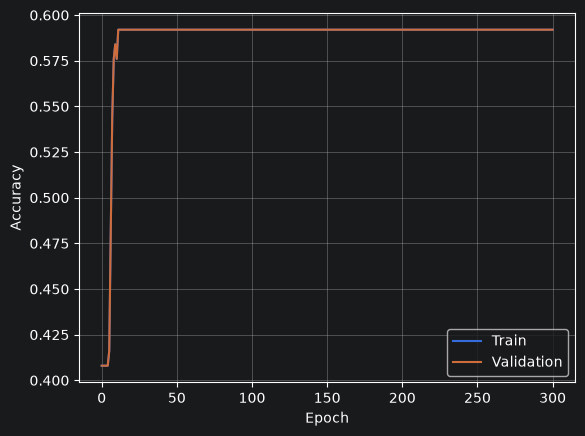

In [46]:
plt.plot(acc , label = "Train")
plt.plot(acc , label = "Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()